# sdcal calibration part


## Overview

This part calculates weighted averages of spectral data at OFF source to use calibration data at ON-source. In sdcal, OFF-source spectral data is retrieved using STATE_ID as a key, with table STATE joined with column OBS_MODE is `OBSERVE_TARGET#OFF_SOURCE`. Spectral data are grouped by STATE_ID, and calibration data are calculated for each group. 

Note that STATE_ID is effectively a sub-scan number which is incremented as observing intent switches. For ALMA TP (SD) observation, target scan (with `OBSERVE_TARGET` intent) consists of `ON_SOURCE` and `OFF_SOURCE` sub-scan intents. The scan executes `ON_SOURCE` and `OFF_SOURCE` sub-scans alternatively. Since the purpose of the calibration is to calculate weighted average of spectral data of `OFF_SOURCE` sub-scan intents _consecutive in time_, STATE_ID inherently and robustly groups `OFF_SOURCE` data into chunks to be averaged together.

The base implementation is: casa6/casatools/src/code/synthesis/MeasurementComponents/SingleDishSkyCal.cc

## Logic

The entry point of this logic is _SingleDishSkyCal::selfGatherAndSolve()_, it executes as belows:

1. getting rows of unflagged OFF sources as reference MeasurementSet by _SingleDishPositionSwitchCal::selectReferenceData(user_selection)_. 
   About ALMA, it has the additional condition of selecting rows: Ignores rows that an amount of channel is 4. This additional condition intends to exclude Water Vapor Radiometer (WVR) data.

2. filling calibration table per reference MeasurementSet by _SingleDishPositionSwitchCal::fillCalibrationTable(reference_data)_. The logic is executed in each block of observation data rows. The blocks are determined by **STATE_ID** as well as other basic metadata, OBSERVATION_ID, PROCESSOR_ID, FIELD_ID, ANTENNA1, FEED1, DATA_DESC_ID (a combination of POLARIZATION_ID and SPECTRAL_WINDOW_ID), and SCAN_NUMBER. Detailed procedure to derive the result from each block is as follows:

    - Calculate reference timestamp of calibrated spectrum as a mean of timestamps in TIME column.
    - Calculate the integration time as a sum of the integration durations in EXPOSURE column.
    - Loop processing below for each row. This logic obtains a weighted average of the valid data with exposure as the weight.
        - get the valid spectrum data $x_{\rm valid}$ and weight $w_{\rm valid}$, masked by the column 'FLAG'. $w_{\rm valid}$ is basically an integration time recoeded in EXPOSURE column. But the weight is set to zero if data is flagged (FLAG value is True).
        - calcurate integrated addition of $w_{\rm valid} \times x_{\rm valid}$. Finally it becomes $\sum w_{\rm valid} \times x_{valid}$
        - calcurate integrated addition of $w_{\rm valid}$. Finally it becomes $\sum w_{\rm valid}$
    - get non-zero $\sum w_{\rm valid}$, then culculate so-called weighted average:
    $$
       \frac{\sum w_{\rm valid} \times x_{\rm valid}}{\sum w_{\rm valid}}
    $$
3. save calibration data into table.



# Reference Python implementation

### input data

In [1]:
import numpy as np

# timestamp
time = np.asarray([1.0, 1.9, 2.8, 3.7])

# effective integration time
exposure = np.asarray([0.9, 0.9, 0.9, 0.9])

# state id
state_ids = np.asarray([5, 5, 5, 5])

# subscan intents 
subscan_intents = {
    1: "OBSERVE_TARGET#OFF_SOURCE",
    2: "OBSERVE_TARGET#ON_SOURCE",
    3: "OBSERVE_TARGET#OFF_SOURCE",
    4: "OBSERVE_TARGET#ON_SOURCE",
    5: "OBSERVE_TARGET#OFF_SOURCE",
    6: "OBSERVE_TARGET#ON_SOURCE",
    7: "OBSERVE_TARGET#OFF_SOURCE"
}    

# The shape of FLAG:bool and DATA:float are (row, polarization, channel), in this example, row:3, pol:2, chan:5.
flag = np.asarray([[[False, False, True, False, False],
                    [True, False, False, False, False]],
                   [[False, False, False, False, False],
                    [False, False, False, False, False]],
                   [[False, False, True, False, False],
                    [True, False, False, False, False]],
                   [[False, False, True, False, False],
                    [True, False, False, False, False]]])
data = np.asarray([[[0.9, 0.95, 1.0, 1.1, 1.0],
                    [0.07, 0.08, 0.07, 0.05, 0.04]],
                   [[0.9, 1.0, 1.1, 1.1, 1.0],
                    [0.09, 0.1, 0.08, 0.07, 0.06]],
                   [[0.8, 0.8, 0.9, 1.0, 0.9],
                    [0.09, 0.09, 0.08, 0.07, 0.06]],
                   [[0.8, 0.8, 0.9, 1.0, 0.9],
                    [0.09, 0.09, 0.08, 0.07, 0.06]]])                    

In [2]:
import matplotlib.pyplot as plt

def output(_data, time_centroid, effective_exposure):
    for i in range(_data.shape[0]):
        plt.plot(_data[i])
    plt.show()
    print(f'time centroid: {time_centroid}, effective exposure: {effective_exposure}')

### The main loop

The Loop below is executed for each row of data and flag.
This logic obtains a weighted average of the valid data with exposure as the weight.

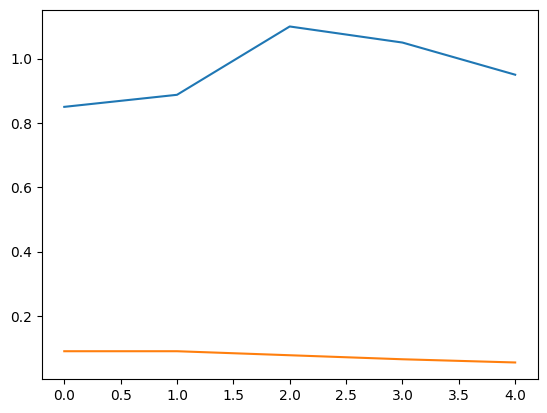

time centroid: 2.3499999999999996, effective exposure: 3.6


In [3]:
unique_state_ids = np.unique(state_ids)
off_source = filter(lambda x: subscan_intents[x] == "OBSERVE_TARGET#OFF_SOURCE", unique_state_ids)
for sid in off_source:
    # select data by STATE_ID
    selection = np.where(state_ids == sid)[0]

    # reference timestamp
    time_centroid = np.mean(time[selection])

    # total integration time
    effective_exposure = np.sum(exposure[selection])

    # OFF_SOURCE spectrum
    block_data = data[selection]
    block_flag = flag[selection]

    x_valid = np.ma.masked_array(block_data, block_flag)
    weight = exposure[selection]
    wx_sum = np.ma.sum(x_valid * weight.reshape((len(weight), 1, 1)), axis=0)

    w_valid = np.logical_not(block_flag) * weight.reshape((len(weight), 1, 1))
    w_sum = np.ma.sum(np.ma.masked_array(w_valid, block_flag), axis=0)
    solution = wx_sum / w_sum

    # output
    output(solution, time_centroid, effective_exposure)